# Chapter 5. Evaluation

## 5.3 Comparison of the Four Denoising Methods

This notebook compares the final adaptive pipelines for anisotropic diffusion, total variation, bilateral filtering, and non-local means on the same test images.

PSNR is the main measure. SSIM, GMSD, and runtime provide supporting comparisons.


In [1]:
from pathlib import Path
from time import perf_counter
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoising_config import (
    FLAT_FRACTION, METHOD_LABELS, METHOD_ORDER, denoise_mapped
)
from src.metrics import calculate_gmsd, calculate_psnr, calculate_ssim
from src.noise import add_gaussian_noise
from src.noise_level_estimators import edge_aware_laplacian_noise_estimate
from src.utils import load_grayscale_image

In [46]:
# Test settings
noise_levels = list(range(2, 16))
seed = 42
num_test_images = 100
n_jobs = 16

force_quality_rerun = False
force_runtime_rerun = False
runtime_image_count = num_test_images

test_dir = project_dir / "data" / "test"
result_dir = project_dir / "results" / "Chapter5_CompareFourDenoisers"
result_dir.mkdir(parents=True, exist_ok=True)

method_styles = {
    "AD": {"color": "#FF8C00", "linestyle": "-", "marker": "o"},
    "TV": {"color": "#32CD32", "linestyle": "--", "marker": "s"},
    "BF": {"color": "#00BFFF", "linestyle": "-.", "marker": "^"},
    "NLM": {"color": "#AB82FF", "linestyle": ":", "marker": "D"}
}

print("Test directory:", test_dir)
print("Noise levels (%):", noise_levels)
print("Flat-region fraction:", f"{FLAT_FRACTION:.0%}")
print("Parallel jobs for quality evaluation:", n_jobs)

Test directory: D:\MScProject\data\test
Noise levels (%): [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Flat-region fraction: 4%
Parallel jobs for quality evaluation: 16


In [3]:
# Load the 100 unseen test images
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(test_dir.rglob(pattern))

image_files = sorted(set(image_files))
if len(image_files) != num_test_images:
    raise FileNotFoundError(
        f"Expected {num_test_images} test images, but found "
        f"{len(image_files)} in {test_dir}"
    )

test_images = [
    (image_file.stem, load_grayscale_image(image_file))
    for image_file in image_files
]

for image_name, clean_image in test_images:
    if clean_image.ndim != 2:
        raise ValueError(f"{image_name} is not a grayscale image")
    if clean_image.min() < 0 or clean_image.max() > 1:
        raise ValueError(f"{image_name} is not normalised to [0, 1]")

print("Number of test images:", len(test_images))

Number of test images: 100


### Adaptive pipeline evaluation

The estimated noise level is passed to each denoiser's calibrated mapping. The same test cases are used for all four methods.

Results are cached by noise level so interrupted runs can continue.


In [4]:
# Use one reproducible seed for each image-noise case
def make_case_seed(image_index, noise_percent):
    noise_index = noise_levels.index(noise_percent)
    return seed + noise_index * num_test_images + image_index


def evaluate_quality_case(method, image_index, image_name, clean_image,
                          noise_percent):
    noisy_image = add_gaussian_noise(
        clean_image, sigma=noise_percent / 100,
        seed=make_case_seed(image_index, noise_percent)
    ).astype(np.float32)

    estimated_percent = 100 * float(
        edge_aware_laplacian_noise_estimate(
            noisy_image, flat_fraction=FLAT_FRACTION
        )
    )
    denoised_image = denoise_mapped(noisy_image, method, estimated_percent)

    if denoised_image.shape != clean_image.shape:
        raise ValueError(f"{method} returned an unexpected shape")
    if not np.isfinite(denoised_image).all():
        raise ValueError(f"{method} returned a non-finite value")

    return {
        "image": image_name,
        "image_index": image_index,
        "true_noise_percent": noise_percent,
        "estimated_noise_percent": estimated_percent,
        "method": method,
        "psnr": calculate_psnr(clean_image, denoised_image),
        "ssim": calculate_ssim(clean_image, denoised_image),
        "gmsd": calculate_gmsd(clean_image, denoised_image)
    }


quality_columns = [
    "image", "image_index", "true_noise_percent",
    "estimated_noise_percent", "method", "psnr", "ssim", "gmsd"
]


def load_or_evaluate_quality(method):
    output_path = result_dir / f"adaptive_quality_{method}.csv"

    if output_path.exists() and not force_quality_rerun:
        current = pd.read_csv(output_path)
        missing = set(quality_columns) - set(current.columns)
        if missing:
            raise ValueError(f"{output_path.name} is missing: {sorted(missing)}")
    else:
        current = pd.DataFrame(columns=quality_columns)

    for noise_percent in noise_levels:
        level_rows = current[current["true_noise_percent"] == noise_percent]
        if len(level_rows) == num_test_images:
            continue

        # Replace an incomplete level before continuing
        current = current[current["true_noise_percent"] != noise_percent]
        outputs = Parallel(n_jobs=n_jobs, prefer="threads", verbose=0)(
            delayed(evaluate_quality_case)(
                method, image_index, image_name, clean_image, noise_percent
            )
            for image_index, (image_name, clean_image) in enumerate(test_images)
        )

        current = pd.concat([current, pd.DataFrame(outputs)], ignore_index=True)
        current = current.sort_values(
            ["true_noise_percent", "image_index"]
        ).reset_index(drop=True)
        current.to_csv(output_path, index=False)
        print(f"{METHOD_LABELS[method]}: completed {noise_percent}% noise")

    expected_rows = num_test_images * len(noise_levels)
    if len(current) != expected_rows:
        raise RuntimeError(
            f"Expected {expected_rows} rows for {method}, but found {len(current)}"
        )

    return current

In [5]:
# Evaluate and save each denoiser separately
quality_parts = []
for method in METHOD_ORDER:
    quality_parts.append(load_or_evaluate_quality(method))

quality_results = pd.concat(quality_parts, ignore_index=True)
quality_results = quality_results.sort_values(
    ["method", "true_noise_percent", "image_index"]
).reset_index(drop=True)

expected_rows = (
    num_test_images * len(noise_levels) * len(METHOD_ORDER)
)
if len(quality_results) != expected_rows:
    raise RuntimeError(
        f"Expected {expected_rows} quality rows, but found {len(quality_results)}"
    )

print("Completed quality measurements:", len(quality_results))
display(quality_results.head())

Anisotropic diffusion: completed 2% noise
Anisotropic diffusion: completed 3% noise
Anisotropic diffusion: completed 4% noise
Anisotropic diffusion: completed 5% noise
Anisotropic diffusion: completed 6% noise
Anisotropic diffusion: completed 7% noise
Anisotropic diffusion: completed 8% noise
Anisotropic diffusion: completed 9% noise
Anisotropic diffusion: completed 10% noise
Anisotropic diffusion: completed 11% noise
Anisotropic diffusion: completed 12% noise
Anisotropic diffusion: completed 13% noise
Anisotropic diffusion: completed 14% noise
Anisotropic diffusion: completed 15% noise
Total variation: completed 2% noise
Total variation: completed 3% noise
Total variation: completed 4% noise
Total variation: completed 5% noise
Total variation: completed 6% noise
Total variation: completed 7% noise
Total variation: completed 8% noise
Total variation: completed 9% noise
Total variation: completed 10% noise
Total variation: completed 11% noise
Total variation: completed 12% noise
Total v

,image,image_index,true_noise_percent,estimated_noise_percent,method,psnr,ssim,gmsd
0,001,0,2,2.930928,AD,32.57976,0.92721,0.017477
1,002,1,2,2.051222,AD,37.291542,0.955519,0.015573
2,003,2,2,2.077381,AD,37.171387,0.945708,0.013592
3,004,3,2,2.058982,AD,37.324663,0.957255,0.012938
4,005,4,2,2.129085,AD,35.361967,0.960693,0.014397


In [57]:
# Average the quality measures at each noise level
level_summary = (
    quality_results.groupby(["method", "true_noise_percent"], as_index=False)
    .agg(psnr=("psnr", "mean"), ssim=("ssim", "mean"),
         gmsd=("gmsd", "mean"))
)

overall_quality = (
    quality_results.groupby("method", as_index=False)
    .agg(mean_psnr=("psnr", "mean"), mean_ssim=("ssim", "mean"),
         mean_gmsd=("gmsd", "mean"))
    .set_index("method").loc[METHOD_ORDER].reset_index()
)


def make_level_table(metric, decimals):
    table = level_summary.pivot(
        index="true_noise_percent", columns="method", values=metric
    )
    table = table[METHOD_ORDER].rename(columns=METHOD_LABELS)
    table.index = [f"{int(level)}%" for level in table.index]
    table.index.name = "True noise level"

    overall = (
        quality_results.groupby("method")[metric]
        .mean().reindex(METHOD_ORDER)
    )
    table.loc["Overall mean"] = overall.to_numpy()
    return table.round(decimals)


psnr_table = make_level_table("psnr", 3)
ssim_table = make_level_table("ssim", 4)
gmsd_table = make_level_table("gmsd", 4)

In [59]:
# Use the same plot style for all quality measures
def plot_quality_curves(metric, ylabel, output_name):
    fig, ax = plt.subplots(figsize=(10.5, 5.8))

    for method in METHOD_ORDER:
        values = level_summary[level_summary["method"] == method]
        ax.plot(
            values["true_noise_percent"], values[metric],
            linewidth=2, markersize=5,
            label=METHOD_LABELS[method], **method_styles[method]
        )

    ax.set_xticks(noise_levels)
    ax.set_xlabel("True noise level (%)", fontsize=13, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=13, labelpad=8)
    ax.tick_params(axis="both", labelsize=13)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(
    frameon=False,
    fontsize=13,
    ncol=2,
    columnspacing=2.0,   # Horizontal spacing between columns
    labelspacing=0.9,    # Vertical spacing between rows
    handlelength=2.3,    # Length of the line in the legend
    handletextpad=0.8    # Space between the line and text
)

    fig.subplots_adjust(left=0.10, right=0.98, top=0.97, bottom=0.13)
    fig.savefig(result_dir / output_name, dpi=300, bbox_inches="tight")
    plt.show()

### PSNR

Mean PSNR across the test noise levels. Higher is better.


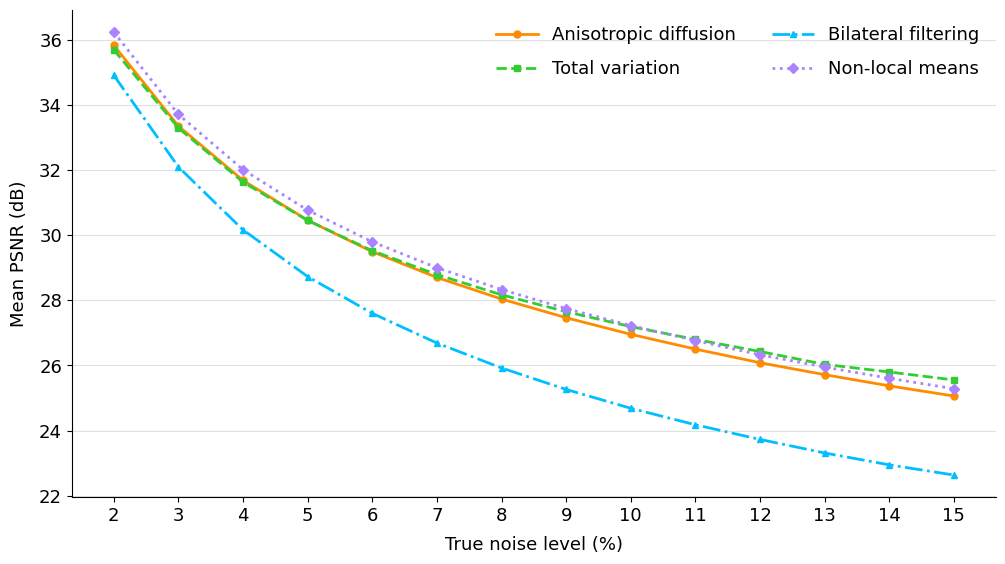

method,Anisotropic diffusion,Total variation,Bilateral filtering,Non-local means
True noise level,,,,
2%,35.841,35.702,34.919,36.247
3%,33.357,33.300,32.101,33.715
4%,31.688,31.637,30.167,32.019
5%,30.464,30.458,28.732,30.774
6%,29.496,29.526,27.602,29.800
7%,28.705,28.793,26.689,29.004
8%,28.042,28.172,25.923,28.334
9%,27.467,27.654,25.263,27.748
10%,26.958,27.194,24.684,27.228


In [62]:
plot_quality_curves(
    "psnr", "Mean PSNR (dB)", "four_denoisers_psnr.png"
)

with pd.option_context("display.float_format", "{:.3f}".format):
    display(psnr_table)

### SSIM

Mean SSIM across the same test cases. Higher is better.


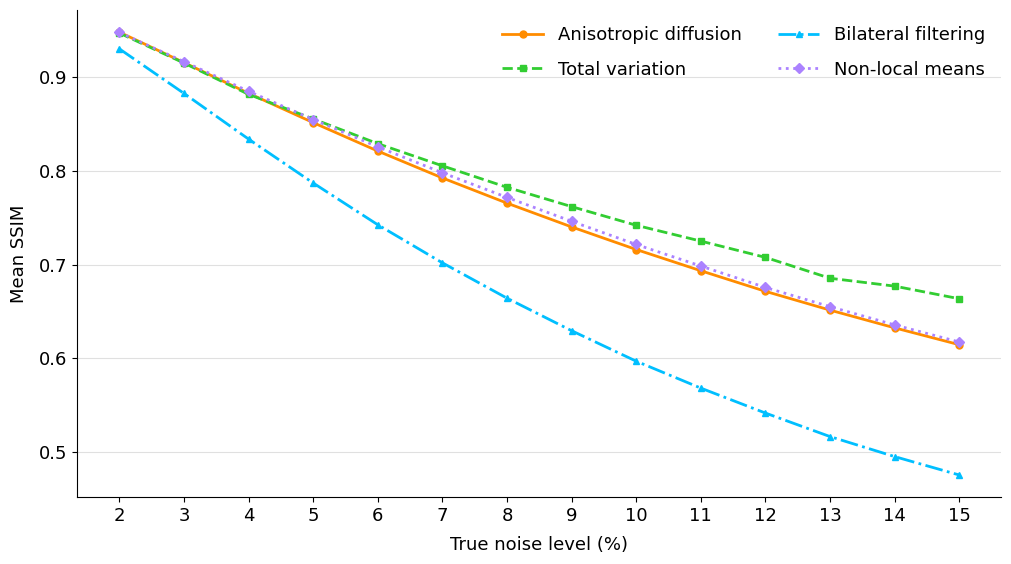

method,Anisotropic diffusion,Total variation,Bilateral filtering,Non-local means
True noise level,,,,
2%,0.9478,0.9468,0.9300,0.9475
3%,0.9154,0.9149,0.8825,0.9164
4%,0.8827,0.8815,0.8338,0.8848
5%,0.8514,0.8553,0.7870,0.8547
6%,0.8211,0.8289,0.7425,0.8256
7%,0.7924,0.8053,0.7019,0.7979
8%,0.7655,0.7824,0.6642,0.7717
9%,0.7402,0.7618,0.6295,0.7462
10%,0.7161,0.7419,0.5970,0.7215


In [65]:
plot_quality_curves(
    "ssim", "Mean SSIM", "four_denoisers_ssim.png"
)

with pd.option_context("display.float_format", "{:.4f}".format):
    display(ssim_table)


### Edge preservation

Mean GMSD across the same test cases. Lower is better.


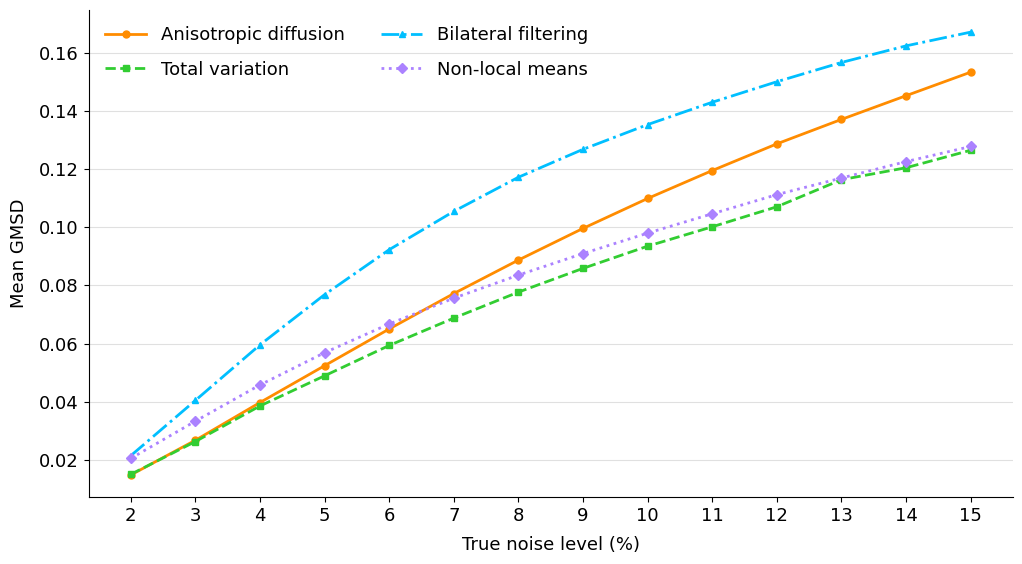

method,Anisotropic diffusion,Total variation,Bilateral filtering,Non-local means
True noise level,,,,
2%,0.0148,0.0150,0.0214,0.0205
3%,0.0267,0.0263,0.0404,0.0333
4%,0.0397,0.0386,0.0596,0.0458
5%,0.0524,0.0489,0.0768,0.0569
6%,0.0650,0.0594,0.0923,0.0667
7%,0.0772,0.0688,0.1055,0.0756
8%,0.0887,0.0777,0.1172,0.0836
9%,0.0996,0.0859,0.1268,0.0910
10%,0.1099,0.0935,0.1353,0.0980


In [64]:
plot_quality_curves(
    "gmsd", "Mean GMSD", "four_denoisers_gmsd.png"
)

with pd.option_context("display.float_format", "{:.4f}".format):
    display(gmsd_table)


### Runtime

Runtime includes noise estimation and denoising only. Results are cached by noise level.


In [35]:
def evaluate_runtime_case(method, image_index, image_name, clean_image,
                          noise_percent):
    noisy_image = add_gaussian_noise(
        clean_image, sigma=noise_percent / 100,
        seed=make_case_seed(image_index, noise_percent)
    ).astype(np.float32)

    start = perf_counter()
    estimated_percent = 100 * float(
        edge_aware_laplacian_noise_estimate(
            noisy_image, flat_fraction=FLAT_FRACTION
        )
    )
    estimation_ms = 1000 * (perf_counter() - start)

    start = perf_counter()
    denoised_image = denoise_mapped(noisy_image, method, estimated_percent)
    denoising_ms = 1000 * (perf_counter() - start)

    if denoised_image.shape != clean_image.shape:
        raise ValueError(f"{method} returned an unexpected shape")
    if not np.isfinite(denoised_image).all():
        raise ValueError(f"{method} returned a non-finite value")

    return {
        "image": image_name,
        "image_index": image_index,
        "true_noise_percent": noise_percent,
        "method": method,
        "estimation_ms": estimation_ms,
        "denoising_ms": denoising_ms,
        "total_ms": estimation_ms + denoising_ms
    }


runtime_columns = [
    "image", "image_index", "true_noise_percent", "method",
    "estimation_ms", "denoising_ms", "total_ms"
]


def load_or_measure_runtime(method):
    output_path = result_dir / (
        f"adaptive_runtime_{method}_{runtime_image_count}_images.csv"
    )

    if output_path.exists() and not force_runtime_rerun:
        current = pd.read_csv(output_path)
        missing = set(runtime_columns) - set(current.columns)
        if missing:
            raise ValueError(f"{output_path.name} is missing: {sorted(missing)}")
    else:
        current = pd.DataFrame(columns=runtime_columns)

    # Warm up the denoiser before timing
    warm_image = test_images[0][1]
    warm_noisy = add_gaussian_noise(
        warm_image, sigma=0.08, seed=make_case_seed(0, 8)
    ).astype(np.float32)
    warm_estimate = 100 * float(
        edge_aware_laplacian_noise_estimate(
            warm_noisy, flat_fraction=FLAT_FRACTION
        )
    )
    denoise_mapped(warm_noisy, method, warm_estimate)

    for noise_percent in noise_levels:
        level_rows = current[current["true_noise_percent"] == noise_percent]
        if len(level_rows) == runtime_image_count:
            continue

        current = current[current["true_noise_percent"] != noise_percent]
        rows = []
        for image_index, (image_name, clean_image) in enumerate(
            test_images[:runtime_image_count]
        ):
            rows.append(evaluate_runtime_case(
                method, image_index, image_name, clean_image, noise_percent
            ))

        current = pd.concat([current, pd.DataFrame(rows)], ignore_index=True)
        current = current.sort_values(
            ["true_noise_percent", "image_index"]
        ).reset_index(drop=True)
        current.to_csv(output_path, index=False)
        print(f"{METHOD_LABELS[method]}: timed {noise_percent}% noise")

    expected_rows = runtime_image_count * len(noise_levels)
    if len(current) != expected_rows:
        raise RuntimeError(
            f"Expected {expected_rows} timing rows for {method}, "
            f"but found {len(current)}"
        )

    return current

In [12]:
# Time one method at a time and keep each completed result
runtime_parts = []
for method in METHOD_ORDER:
    runtime_parts.append(load_or_measure_runtime(method))

runtime_results = pd.concat(runtime_parts, ignore_index=True)
runtime_results = runtime_results.sort_values(
    ["method", "true_noise_percent", "image_index"]
).reset_index(drop=True)

print("Completed runtime measurements:", len(runtime_results))
display(runtime_results.head())

Anisotropic diffusion: timed 2% noise
Anisotropic diffusion: timed 3% noise
Anisotropic diffusion: timed 4% noise
Anisotropic diffusion: timed 5% noise
Anisotropic diffusion: timed 6% noise
Anisotropic diffusion: timed 7% noise
Anisotropic diffusion: timed 8% noise
Anisotropic diffusion: timed 9% noise
Anisotropic diffusion: timed 10% noise
Anisotropic diffusion: timed 11% noise
Anisotropic diffusion: timed 12% noise
Anisotropic diffusion: timed 13% noise
Anisotropic diffusion: timed 14% noise
Anisotropic diffusion: timed 15% noise
Total variation: timed 2% noise
Total variation: timed 3% noise
Total variation: timed 4% noise
Total variation: timed 5% noise
Total variation: timed 6% noise
Total variation: timed 7% noise
Total variation: timed 8% noise
Total variation: timed 9% noise
Total variation: timed 10% noise
Total variation: timed 11% noise
Total variation: timed 12% noise
Total variation: timed 13% noise
Total variation: timed 14% noise
Total variation: timed 15% noise
Bilatera

,image,image_index,true_noise_percent,method,estimation_ms,denoising_ms,total_ms
0,001,0,2,AD,11.8902,8.2934,20.1836
1,002,1,2,AD,20.1534,8.0977,28.2511
2,003,2,2,AD,18.1918,7.0922,25.284
3,004,3,2,AD,12.4528,6.8282,19.281
4,005,4,2,AD,10.9944,6.7639,17.7583


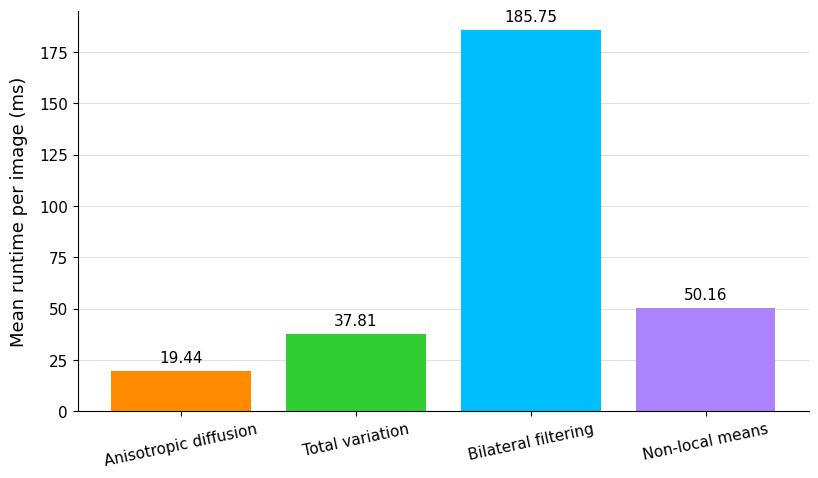

method,Anisotropic diffusion,Total variation,Bilateral filtering,Non-local means
True noise level,,,,
2%,20.81,27.35,190.50,47.40
3%,18.50,29.90,190.00,49.09
4%,18.85,32.94,185.08,51.11
5%,19.15,34.96,184.42,49.03
6%,18.88,39.23,185.43,50.84
7%,19.61,37.92,184.60,49.40
8%,21.14,38.82,187.08,51.66
9%,19.83,41.25,184.57,50.47
10%,19.32,41.41,185.53,49.01


In [67]:
# Summarise total runtime by noise level and method
runtime_level_summary = (
    runtime_results.groupby(["method", "true_noise_percent"], as_index=False)
    .agg(mean_total_ms=("total_ms", "mean"))
)

runtime_table = runtime_level_summary.pivot(
    index="true_noise_percent", columns="method", values="mean_total_ms"
)
runtime_table = runtime_table[METHOD_ORDER].rename(columns=METHOD_LABELS)
runtime_table.index = [f"{int(level)}%" for level in runtime_table.index]
runtime_table.index.name = "True noise level"

overall_runtime = (
    runtime_results.groupby("method", as_index=False)
    .agg(
        estimation_ms=("estimation_ms", "mean"),
        denoising_ms=("denoising_ms", "mean"),
        total_ms=("total_ms", "mean")
    )
    .set_index("method").loc[METHOD_ORDER].reset_index()
)

runtime_table.loc["Overall mean"] = overall_runtime["total_ms"].to_numpy()
runtime_table = runtime_table.round(2)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
bar_colours = [method_styles[method]["color"] for method in METHOD_ORDER]

bars = ax.bar(
    [METHOD_LABELS[method] for method in METHOD_ORDER],
    overall_runtime["total_ms"], color=bar_colours
)

# Add the mean runtime above each bar
ax.bar_label(bars,fmt="%.2f",padding=4,fontsize=11)

ax.set_ylabel("Mean runtime per image (ms)", fontsize=13, labelpad=8)
ax.tick_params(axis="x", labelrotation=12, labelsize=11)
ax.tick_params(axis="y", labelsize=11)
ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.subplots_adjust(left=0.12, right=0.98, top=0.97, bottom=0.20)
fig.savefig(
    result_dir / "four_denoisers_runtime.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

with pd.option_context("display.float_format", "{:.2f}".format):
    display(runtime_table)



### Overall comparison

Overall mean quality and runtime across all test cases.


In [66]:
# Combine quality and runtime in one overall table
overall_performance = overall_quality.merge(overall_runtime, on="method")
overall_performance["Method"] = overall_performance["method"].map(METHOD_LABELS)

overall_table = overall_performance[[
    "Method", "mean_psnr", "mean_ssim", "mean_gmsd", "total_ms"
]].rename(columns={
    "mean_psnr": "Mean PSNR (dB) ↑",
    "mean_ssim": "Mean SSIM ↑",
    "mean_gmsd": "Mean GMSD ↓",
    "total_ms": "Runtime per image (ms) ↓"
})

# Keep the numerical table rounded
overall_table = overall_table.round({
    "Mean PSNR (dB) ↑": 3,
    "Mean SSIM ↑": 4,
    "Mean GMSD ↓": 4,
    "Runtime per image (ms) ↓": 2
})

# Create a formatted copy for display
overall_table_formatted = overall_table.copy()
overall_table_formatted["Mean PSNR (dB) ↑"] = (overall_table["Mean PSNR (dB) ↑"].map("{:.3f}".format))
overall_table_formatted["Mean SSIM ↑"] = (overall_table["Mean SSIM ↑"].map("{:.4f}".format))
overall_table_formatted["Mean GMSD ↓"] = (overall_table["Mean GMSD ↓"].map("{:.4f}".format))
overall_table_formatted["Runtime per image (ms) ↓"] = (overall_table["Runtime per image (ms) ↓"].map("{:.2f}".format))

display(overall_table_formatted)


# Report the leading method for each measure
best_psnr = overall_performance.loc[overall_performance["mean_psnr"].idxmax()]
best_ssim = overall_performance.loc[overall_performance["mean_ssim"].idxmax()]
best_gmsd = overall_performance.loc[overall_performance["mean_gmsd"].idxmin()]
fastest = overall_performance.loc[overall_performance["total_ms"].idxmin()]

print("Highest mean PSNR:", METHOD_LABELS[best_psnr["method"]])
print("Highest mean SSIM:", METHOD_LABELS[best_ssim["method"]])
print("Lowest mean GMSD:", METHOD_LABELS[best_gmsd["method"]])
print("Lowest mean runtime:", METHOD_LABELS[fastest["method"]])

,Method,Mean PSNR (dB) ↑,Mean SSIM ↑,Mean GMSD ↓,Runtime per image (ms) ↓
0,Anisotropic diffusion,28.626,0.7640,0.0899,19.44
1,Total variation,28.790,0.7841,0.0775,37.81
2,Bilateral filtering,26.634,0.6690,0.1110,185.75
3,Non-local means,28.915,0.7678,0.0825,50.16


Highest mean PSNR: Non-local means
Highest mean SSIM: Total variation
Lowest mean GMSD: Total variation
Lowest mean runtime: Anisotropic diffusion
